# Corales de Panamá y eventos de El Niño: un análisis con datos abiertos
## Análisis: corales y temperatura del mar

**Pregunta de investigación:** ¿Cómo ha cambiado el estrés térmico en el Caribe y el Pacífico de Panamá
desde 1985, y qué tan expuestos están los corales registrados en cada costa a un riesgo potencial de blanqueamiento?

Por Angela Pérez y Edwin De Frías

## Contexto

Panamá tiene unos 800 km² de arrecifes de coral, más del 97 % en el Caribe. Los arrecifes sostienen la pesca
(cientos de especies de peces dependen de ellos), el turismo y protegen las costas de las olas.
Con el calentamiento del mar, los corales pueden blanquearse y morir si el calor dura demasiado.
En 2026, además, se discutió en la Asamblea un proyecto de ley que modificaba la protección de los arrecifes
(Ley 304 de 2022); el proyecto fue vetado por el Ejecutivo.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

## 1. Cargamos los datos limpios

In [2]:
corales = pd.read_csv("../datos/limpios/corales_limpio.csv")
temperatura = pd.read_csv("../datos/limpios/temperatura_limpio.csv")

print("Corales:", corales.shape)
print("Temperatura:", temperatura.shape)

Corales: (13260, 34)
Temperatura: (61136, 15)


## 2. Exploración inicial: ¿se pueden comparar los corales con la temperatura año por año?

In [3]:
corales_cruce = corales[
    corales["anio"].notna()
    & (corales["costa"] != "sin dato")
    & (corales["zona"] == "somera")
].copy()

corales_cruce["anio"] = corales_cruce["anio"].astype(int)
corales_cruce = corales_cruce[corales_cruce["anio"] >= 1985]

print("Registros para el cruce:", len(corales_cruce))
corales_cruce["costa"].value_counts()

print("Corales limpios:", len(corales))
print("Con año:", corales["anio"].notna().sum())
print("Con costa conocida:", (corales["costa"] != "sin dato").sum())
print("Someros:", (corales["zona"] == "somera").sum())
print("Cumplen todo y son desde 1985:", len(corales_cruce))
print(corales_cruce["costa"].value_counts())

Registros para el cruce: 8738
Corales limpios: 13260
Con año: 12337
Con costa conocida: 12069
Someros: 9452
Cumplen todo y son desde 1985: 8738
costa
Caribe      8604
Pacífico     134
Name: count, dtype: int64


###  Resumen de corales por año y costa

Se agrupan los corales por año y costa, y en cada grupo se calcula:
- `registros`: cuántos registros de corales hay (mide el **esfuerzo de muestreo**).
- `especies`: cuántas especies distintas se registraron.

Como vimos, la cantidad de registros depende de cuánto se muestreó (por ejemplo, el monitoreo
de AGRRA en 2002), no de cuántos corales había. Por eso también se cuentan las especies distintas.

In [4]:
resumen_corales = corales_cruce.groupby(["anio", "costa"]).agg(
    registros=("gbif_id", "count"),
    especies=("species", "nunique"),
).reset_index()

print("Filas del resumen:", len(resumen_corales))
resumen_corales.head(10)

Filas del resumen: 21


,anio,costa,registros,especies
0,1986,Caribe,2,1
1,1986,Pacífico,2,0
2,1987,Caribe,4,2
3,1988,Caribe,2,1
4,1989,Caribe,2,1
5,1989,Pacífico,31,2
6,1990,Caribe,31,1
7,1994,Caribe,21,3
8,1995,Caribe,25,3
9,1996,Caribe,18,3


In [5]:
print(resumen_corales.to_string())

    anio     costa  registros  especies
0   1986    Caribe          2         1
1   1986  Pacífico          2         0
2   1987    Caribe          4         2
3   1988    Caribe          2         1
4   1989    Caribe          2         1
5   1989  Pacífico         31         2
6   1990    Caribe         31         1
7   1994    Caribe         21         3
8   1995    Caribe         25         3
9   1996    Caribe         18         3
10  1997    Caribe         27         3
11  1998    Caribe         21         3
12  1998  Pacífico          1         0
13  2000    Caribe         44         3
14  2000  Pacífico          1         1
15  2001    Caribe          8         3
16  2002    Caribe       8298        30
17  2004    Caribe          1         0
18  2006    Caribe        100         2
19  2021  Pacífico         40         0
20  2022  Pacífico         59         0


In [6]:
resumen_corales.sort_values("registros", ascending=False).head(5)

,anio,costa,registros,especies
16,2002,Caribe,8298,30
18,2006,Caribe,100,2
20,2022,Pacífico,59,0
13,2000,Caribe,44,3
19,2021,Pacífico,40,0


### Hallazgo: los datos de corales no permiten un análisis año por año

Al resumir los registros de corales por año y costa (desde 1985, someros y con costa conocida)
se encontró que:

- Solo hay datos en **21 de las 82 combinaciones** posibles de año y costa: hay muchos años sin registros.
- **2002 concentra el 95 % de los registros** (8,298 de 8,738) y 30 especies, por el monitoreo de AGRRA
  en el Caribe. Ningún otro año supera 3 especies.
- No hay registros de corales **con profundidad anotada** en los eventos de El Niño más fuertes
  (2009-10, 2015-16 y 2023-24). Sí hay observaciones de iNaturalist en esos años, pero sin profundidad,
  por lo que no entraron en el análisis.

Los registros de GBIF muestran **presencia** de corales en ciertos momentos, no un monitoreo continuo.
Por eso no se puede medir si un año caliente cambió los corales.

### Ajuste de la pregunta: de año por año a costa por costa

En lugar de unir los datasets por año, se unen **por costa**:
1. La temperatura (serie diaria completa desde 1985) muestra cómo ha cambiado el estrés térmico en cada costa,
   usando el nivel de alerta de blanqueamiento de NOAA como un semáforo.
2. Los corales muestran qué especies viven en cada costa.
3. Juntos responden qué tan expuestos están los corales de cada costa a un **riesgo potencial** de blanqueamiento.

### Secciones del análisis
- Semáforo de estrés térmico por costa
- ¿Se ha calentado el mar?
- Corales por costa
- Exposición de los corales al riesgo
- ¿Cómo va 2026?
- Conclusiones y limitaciones

## 3. Semáforo de estrés térmico por costa

**Niveles de alerta de blanqueamiento de NOAA:**

| Nivel | Nombre en NOAA | Significado |
|---|---|---|
| 0 | No Stress | Sin estrés térmico |
| 1 | Bleaching Watch | Vigilancia: la temperatura empieza a subir |
| 2 | Bleaching Warning | Advertencia: el estrés se está acumulando |
| 3 | Alert Level 1 | Blanqueamiento probable (DHW ≥ 4) |
| 4 | Alert Level 2 | Blanqueamiento severo y mortalidad probable (DHW ≥ 8) |
| 5 | Alert Level 3 | Riesgo de mortalidad de varias especies (DHW ≥ 12) |
| 6 | Alert Level 4 | Riesgo de mortalidad severa (DHW ≥ 16) |
| 7 | Alert Level 5 | Riesgo de mortalidad casi total (DHW ≥ 20) |

NOAA amplió su escala con los niveles 5 a 7 para los casos de estrés térmico extremo.
En los datos aparecen todos los niveles, incluido el 7.

El nivel de cada costa es el más alto de sus dos estaciones virtuales
(por ejemplo, el Caribe toma el mayor entre Atlantic East y Atlantic West).

In [7]:
alerta_diaria = temperatura.groupby(["costa", "anio", "fecha"])["alerta"].max().reset_index()

print("Filas:", len(alerta_diaria))
alerta_diaria.head()

Filas: 30568


,costa,anio,fecha,alerta
0,Caribe,1985,1985-01-01,NaN
1,Caribe,1985,1985-01-02,NaN
2,Caribe,1985,1985-01-03,NaN
3,Caribe,1985,1985-01-04,NaN
4,Caribe,1985,1985-01-05,NaN


In [8]:
alerta_diaria["nivel_3_o_mas"] = alerta_diaria["alerta"] >= 3
alerta_diaria["nivel_4"] = alerta_diaria["alerta"] >= 4

In [9]:
semaforo = alerta_diaria.groupby(["costa", "anio"]).agg(
    alerta_max=("alerta", "max"),
    dias_nivel_3_o_mas=("nivel_3_o_mas", "sum"),
    dias_nivel_4=("nivel_4", "sum"),
).reset_index()

print("Filas del semáforo:", len(semaforo))
semaforo.sort_values("dias_nivel_4", ascending=False).head(10)

Filas del semáforo: 84


,costa,anio,alerta_max,dias_nivel_3_o_mas,dias_nivel_4
39,Caribe,2024,6.0,221,204
38,Caribe,2023,7.0,204,191
81,Pacífico,2024,6.0,255,191
80,Pacífico,2023,6.0,215,169
83,Pacífico,2026,6.0,170,149
73,Pacífico,2016,5.0,130,90
35,Caribe,2020,5.0,132,63
55,Pacífico,1998,5.0,104,61
25,Caribe,2010,4.0,114,49
82,Pacífico,2025,5.0,65,45


In [10]:
semaforo["alerta_max"].value_counts().sort_index()

alerta_max
1.0     6
2.0    53
3.0     7
4.0     8
5.0     5
6.0     4
7.0     1
Name: count, dtype: int64

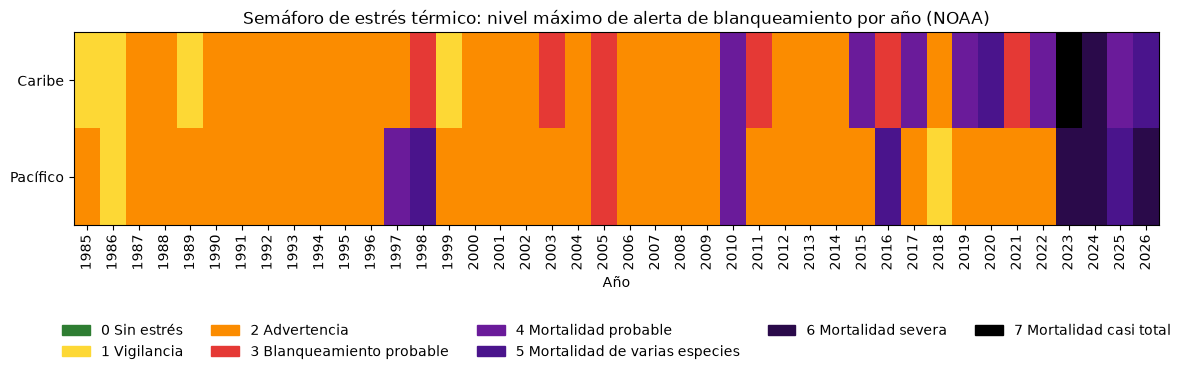

In [11]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Tabla tipo calendario: costas en filas, años en columnas
tabla_semaforo = semaforo.pivot(index="costa", columns="anio", values="alerta_max")

# Un color y un nombre por nivel, del 0 al 7
colores = ["#2e7d32", "#fdd835", "#fb8c00", "#e53935", "#6a1b9a", "#4a148c", "#2a0a4a", "#000000"]
nombres = ["0 Sin estrés", "1 Vigilancia", "2 Advertencia", "3 Blanqueamiento probable",
           "4 Mortalidad probable", "5 Mortalidad de varias especies",
           "6 Mortalidad severa", "7 Mortalidad casi total"]

fig, ax = plt.subplots(figsize=(14, 2.5))
ax.imshow(tabla_semaforo, cmap=ListedColormap(colores), vmin=-0.5, vmax=7.5, aspect="auto")

ax.set_yticks(range(2), tabla_semaforo.index)
ax.set_xticks(range(len(tabla_semaforo.columns)), tabla_semaforo.columns, rotation=90)

ax.set_title("Semáforo de estrés térmico: nivel máximo de alerta de blanqueamiento por año (NOAA)")
ax.set_xlabel("Año")

leyenda = [Patch(color=c, label=n) for c, n in zip(colores, nombres)]
ax.legend(handles=leyenda, ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.45), frameon=False)

plt.show()

In [12]:
semaforo[semaforo["alerta_max"] >= 5].sort_values("anio")

,costa,anio,alerta_max,dias_nivel_3_o_mas,dias_nivel_4
55,Pacífico,1998,5.0,104,61
73,Pacífico,2016,5.0,130,90
35,Caribe,2020,5.0,132,63
38,Caribe,2023,7.0,204,191
80,Pacífico,2023,6.0,215,169
39,Caribe,2024,6.0,221,204
81,Pacífico,2024,6.0,255,191
82,Pacífico,2025,5.0,65,45
41,Caribe,2026,5.0,111,28
83,Pacífico,2026,6.0,170,149


**Observaciones:**
- Durante las primeras tres décadas predomina el nivel 2 (Advertencia). Los años con nivel 3 o superior son pocos y coinciden con eventos de El Niño, como 1997–98.
- Desde 2015 el patrón cambia: los niveles 4 o superiores aparecen casi todos los años en al menos una costa.
- De los 9 casos (costa-año) con nivel 5 o superior, 8 ocurrieron desde 2016.
- El Caribe llegó en 2023 al nivel 7 (mortalidad casi total), el único caso de toda la serie.
- El Pacífico ha estado en nivel 5 o 6 cada año desde 2023, hasta la fecha de la última descarga.
- Desde 1985 no hay ningún año sin estrés térmico (ningún cuadro verde).

## 4. ¿Se ha calentado el mar?

Se calcula la **anomalía promedio** de cada año y costa: cuántos grados por encima (+) o por debajo (−)
de lo normal estuvo el mar. Se usa solo años completos (sin 2026), para no comparar un año
incompleto con años completos.

In [13]:
anual = temperatura[temperatura["anio_completo"]].groupby(["anio", "costa"])["anomalia"].mean().reset_index()

tabla_anual = anual.pivot(index="anio", columns="costa", values="anomalia")
tabla_anual.tail()

costa,Caribe,Pacífico
anio,,
2021,0.851775,0.745072
2022,0.953955,0.533089
2023,1.295306,1.252568
2024,1.631832,1.110588
2025,1.082538,1.107172


Temperatura del mar por año (NOAA)

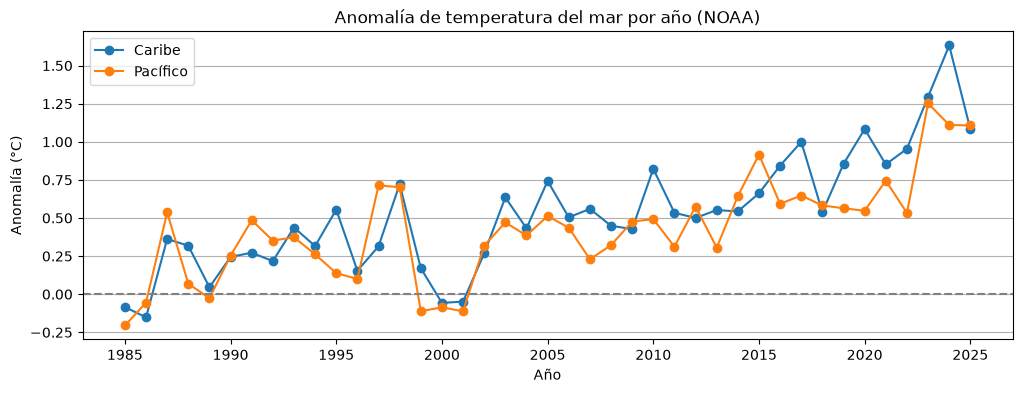

In [14]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(tabla_anual.index, tabla_anual["Caribe"], marker="o", label="Caribe")
ax.plot(tabla_anual.index, tabla_anual["Pacífico"], marker="o", label="Pacífico")

ax.axhline(0, color="gray", linestyle="--")   # línea de "lo normal"

ax.set_title("Anomalía de temperatura del mar por año (NOAA)")
ax.set_xlabel("Año")
ax.set_ylabel("Anomalía (°C)")
ax.legend()
ax.grid(axis="y")
plt.show()

Resumen por década

In [15]:
anual["decada"] = (anual["anio"] // 10) * 10

por_decada = anual.groupby(["decada", "costa"])["anomalia"].mean().round(2).reset_index()
por_decada.pivot(index="decada", columns="costa", values="anomalia")

costa,Caribe,Pacífico
decada,,
1980,0.10,0.06
1990,0.34,0.33
2000,0.39,0.30
2010,0.69,0.56
2020,1.15,0.88


**Observaciones:**
- Hasta 2001, la anomalía se mantiene cerca de 0 °C: la temperatura estaba cerca de lo normal,
  e incluso hubo años más fríos que lo normal.
- Desde 2002, todos los años están por encima de lo normal, y desde 2023 la anomalía supera 1 °C en ambas costas.
- El valor más alto es el Caribe en 2024: +1.63 °C sobre lo normal.
- Los picos coinciden con eventos de El Niño (1997-98, 2010, 2015-16, 2023-24), pero cada pico es más alto que el anterior.
- Por década, la anomalía promedio subió en ambas costas: en el Caribe pasó de 0.10 °C en los años 80
  a 1.15 °C en los años 2020, y en el Pacífico, de 0.06 °C a 0.88 °C.
- El Caribe se calienta más rápido que el Pacífico, y el mayor aumento ocurrió entre los años 2010 y 2020.
- Nota: la década de 2020 incluye solo de 2020 a 2025, porque 2026 está incompleto.

## 5. Corales por costa

Se revisan los corales registrados en cada costa. Como ya no se unen los datos por año, se usan
**todos los registros con costa conocida y de zona somera**, sin importar el año.
Así se aprovechan más datos, sobre todo del Pacífico.

In [16]:
corales_costa = corales[
    (corales["costa"] != "sin dato")
    & (corales["zona"] == "somera")
].copy()

resumen_costa = corales_costa.groupby("costa").agg(
    registros=("gbif_id", "count"),
    especies=("species", "nunique"),
    generos=("genus", "nunique"),
).reset_index()

resumen_costa

,costa,registros,especies,generos
0,Caribe,8807,49,29
1,Pacífico,210,18,11


### Mapa: corales someros y estaciones de temperatura

Cada punto es un registro de coral somero, coloreado por costa. Las estrellas son las 4 estaciones
virtuales de NOAA Coral Reef Watch que miden la temperatura del mar.

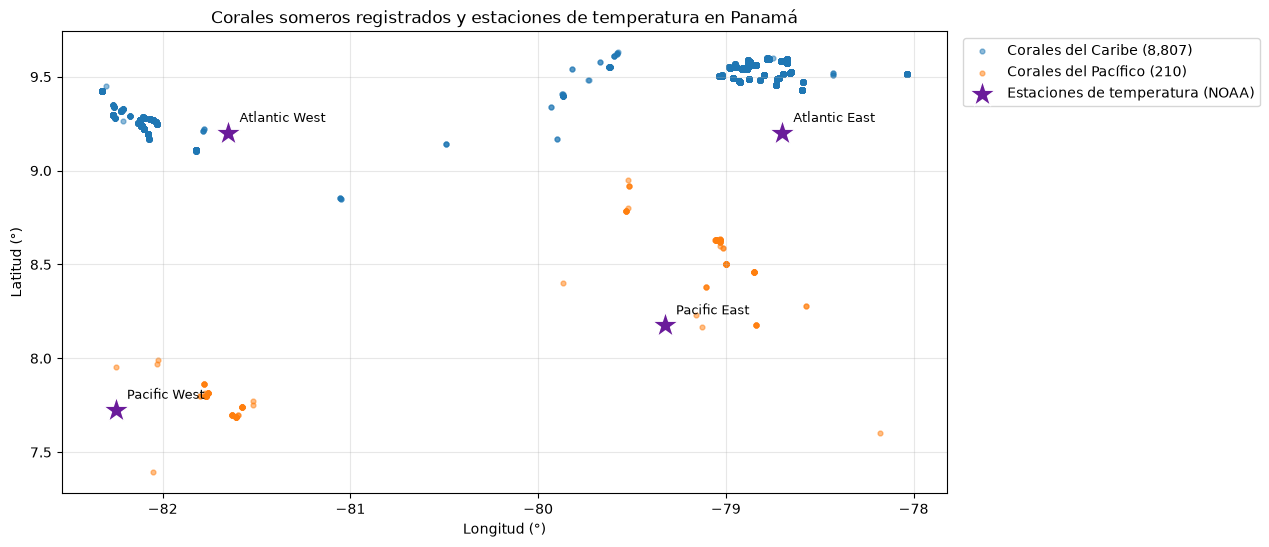

In [17]:
# Coordenadas de las 4 estaciones de NOAA (del notebook de limpieza de temperatura)
estaciones = pd.DataFrame({
    "estacion": ["Atlantic East", "Atlantic West", "Pacific East", "Pacific West"],
    "longitud": [-78.700, -81.650, -79.325, -82.250],
    "latitud": [9.200, 9.200, 8.175, 7.725],
})

colores_costa = {"Caribe": "#1f77b4", "Pacífico": "#ff7f0e"}

fig, ax = plt.subplots(figsize=(13, 6))

# 1. Los corales, un color por costa
for costa, grupo in corales_costa.groupby("costa"):
    ax.scatter(grupo["longitud"], grupo["latitud"], s=12, alpha=0.5,
               color=colores_costa[costa], label=f"Corales del {costa} ({len(grupo):,})")

# 2. Las estaciones de NOAA, como estrellas
ax.scatter(estaciones["longitud"], estaciones["latitud"], marker="*", s=400,
           color="#6a1b9a", edgecolor="white", label="Estaciones de temperatura (NOAA)")

for _, fila in estaciones.iterrows():
    ax.annotate(fila["estacion"], (fila["longitud"], fila["latitud"]),
                textcoords="offset points", xytext=(8, 8), fontsize=9)

ax.set_title("Corales someros registrados y estaciones de temperatura en Panamá")
ax.set_xlabel("Longitud (°)")
ax.set_ylabel("Latitud (°)")
ax.set_aspect("equal")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(alpha=0.3)
plt.show()

**Observaciones del mapa:**
- Los registros de corales dibujan las costas de Panamá: en el Caribe se concentran en Bocas del Toro,
  Colón-Portobelo y Guna Yala; en el Pacífico, en el golfo de Chiriquí (zona de Coiba) y el golfo de Panamá
  (Las Perlas).
- Guna Yala tiene la mayor concentración de registros, lo que coincide con que ahí está la mayor área
  de arrecifes del país.
- Cada estación de temperatura de NOAA está cerca de un grupo de corales, por lo que sus datos representan
  las condiciones de las zonas donde viven los corales registrados.
- Los corales del Pacífico son muchos menos y están más dispersos, lo que refleja el menor muestreo
  en esa costa.

In [18]:
for costa, grupo in corales_costa.groupby("costa"):
    print(f"--- {costa} ---")
    print(grupo["species"].value_counts().head(5).to_string())
    print()

--- Caribe ---
species
Agaricia tenuifolia    1816
Porites astreoides     1274
Orbicella faveolata     767
Porites furcata         637
Colpophyllia natans     624

--- Pacífico ---
species
Porites lobata            27
Porites panamensis        12
Pocillopora damicornis     8
Pavona gigantea            8
Tubastraea coccinea        8



**Observaciones:**
- El Caribe tiene 8,807 registros someros de 49 especies (29 géneros); el Pacífico, 210 registros de 18 especies (11 géneros).
- Aunque el Caribe tiene 42 veces más registros, tiene solo unas 2.7 veces más especies.
  Esta proporción coincide con la diversidad conocida de Panamá (unas 70 especies en el Caribe y 26 en el Pacífico).
- El género Porites es de los más registrados en ambas costas, con especies distintas en cada una.
- En el Pacífico aparece Pocillopora damicornis, del género afectado en blanqueamientos recientes en Coiba,
  Las Perlas e Isla Iguana.

Se revisa por qué el Pacífico tiene solo 210 registros someros, cuando en total tiene 730.

In [19]:
corales[corales["costa"] == "Pacífico"]["zona"].value_counts()

zona
sin dato    442
somera      210
profunda     78
Name: count, dtype: int64

Se prueba un filtro más amplio: todos los registros excepto los profundos (someros + sin dato), para ver si cambia el número de especies.

In [20]:
sin_profundos = corales[
    (corales["costa"] != "sin dato")
    & (corales["zona"] != "profunda")
]

comparacion_filtros = pd.DataFrame({
    "solo someros": corales_costa.groupby("costa")["species"].nunique(),
    "someros + sin dato": sin_profundos.groupby("costa")["species"].nunique(),
})
comparacion_filtros

,solo someros,someros + sin dato
costa,,
Caribe,49,161
Pacífico,18,42


In [21]:
especies_someras = set(corales_costa["species"].dropna())
especies_sin_dato = set(sin_profundos["species"].dropna())

solo_en_sin_dato = especies_sin_dato - especies_someras
print("Especies que solo aparecen en 'sin dato':", len(solo_en_sin_dato))

# ¿De qué familias son?
sin_profundos[sin_profundos["species"].isin(solo_en_sin_dato)]["family"].value_counts().head(8)

Especies que solo aparecen en 'sin dato': 126


family
Caryophylliidae    237
Merulinidae        132
Poritidae          128
Montastraeidae     124
Pocilloporidae      95
Faviidae            93
Astrocoeniidae      57
Agariciidae         53
Name: count, dtype: int64

In [22]:
registros_extra = sin_profundos[sin_profundos["species"].isin(solo_en_sin_dato)]
print(registros_extra["institution_code"].value_counts().head(5))
print("Sin año:", registros_extra["anio"].isna().sum(), "de", len(registros_extra))

institution_code
USNM           734
NIWA           264
iNaturalist     41
sin dato        27
HEX             18
Name: count, dtype: int64
Sin año: 48 de 1107


### Decisión: se usan solo los corales someros

Se probó incluir los registros sin profundidad ("sin dato"). Con ellos, el número de especies sube a 161
en el Caribe y 42 en el Pacífico, más del doble de las especies conocidas en Panamá (unas 70 y 26).

Las 126 especies que solo aparecen en esos registros vienen de fuentes mezcladas: principalmente la
colección del museo Smithsonian (USNM), con muchos corales de la familia Caryophylliidae (corales profundos
y solitarios), y observaciones de NIWA e iNaturalist. Como no se puede saber cuáles de esos registros
son corales someros y cuáles son profundos o dudosos, se conservan solo los registros someros,
que coinciden con la diversidad real de Panamá.

### Especies exclusivas y compartidas

Se comparan las especies registradas en cada costa para ver cuáles viven solo en el Caribe,
solo en el Pacífico o en ambas costas.

In [23]:
caribe = set(corales_costa[corales_costa["costa"] == "Caribe"]["species"].dropna())
pacifico = set(corales_costa[corales_costa["costa"] == "Pacífico"]["species"].dropna())

compartidas = caribe & pacifico
solo_caribe = caribe - pacifico
solo_pacifico = pacifico - caribe

print("Especies en el Caribe:", len(caribe))
print("Especies en el Pacífico:", len(pacifico))
print("Compartidas:", len(compartidas))
print("Solo en el Caribe:", len(solo_caribe))
print("Solo en el Pacífico:", len(solo_pacifico))
print()
print("Especies compartidas:", sorted(compartidas))

Especies en el Caribe: 49
Especies en el Pacífico: 18
Compartidas: 0
Solo en el Caribe: 49
Solo en el Pacífico: 18

Especies compartidas: []


In [24]:
generos_caribe = set(corales_costa[corales_costa["costa"] == "Caribe"]["genus"].dropna())
generos_pacifico = set(corales_costa[corales_costa["costa"] == "Pacífico"]["genus"].dropna())

print("Géneros compartidos:", sorted(generos_caribe & generos_pacifico))

Géneros compartidos: ['Astrangia', 'Balanophyllia', 'Caryophyllia', 'Porites']


**Observaciones:**
- No hay ninguna especie de coral compartida entre el Caribe y el Pacífico: las 49 especies del Caribe
  y las 18 del Pacífico son exclusivas de su costa.
- Esto se explica por el cierre del istmo de Panamá, hace unos 3 millones de años, que separó
  los dos océanos. Desde entonces, los corales de cada lado evolucionaron por separado.
- A nivel de género sí hay coincidencias (Astrangia, Balanophyllia, Caryophyllia y Porites),
  lo que muestra que tienen ancestros comunes. De ellos, solo Porites construye arrecifes.
- Por eso, cada costa tiene corales únicos: si se pierde un arrecife, sus especies no se encuentran
  en la otra costa.

## 6. Exposición de los corales al riesgo

Se unen los dos datasets **por costa**: para cada costa se junta la cantidad de especies de coral
con las medidas de estrés térmico (anomalía por década y días en nivel 4 o superior de alerta).

In [25]:
anomalias = por_decada.pivot(index="costa", columns="decada", values="anomalia")
anomalias = anomalias[[1980, 2020]].rename(columns={1980: "anomalia_1980s", 2020: "anomalia_2020s"})
anomalias = anomalias.rename_axis(columns=None).reset_index()
anomalias

,costa,anomalia_1980s,anomalia_2020s
0,Caribe,0.10,1.15
1,Pacífico,0.06,0.88


In [26]:
semaforo_completo = semaforo[semaforo["anio"] < 2026].copy()

semaforo_completo["periodo"] = "1985-2014"
semaforo_completo.loc[semaforo_completo["anio"] >= 2015, "periodo"] = "2015-2025"

dias = semaforo_completo.groupby(["costa", "periodo"])["dias_nivel_4"].mean().round(1).reset_index()
dias = dias.pivot(index="costa", columns="periodo", values="dias_nivel_4")
dias = dias.rename(columns={"1985-2014": "dias_n4_1985_2014", "2015-2025": "dias_n4_2015_2025"}).reset_index()
dias

periodo,costa,dias_n4_1985_2014,dias_n4_2015_2025
0,Caribe,1.6,53.5
1,Pacífico,2.8,45.0


In [27]:
exposicion = resumen_costa.merge(anomalias, on="costa").merge(dias, on="costa")
exposicion

,costa,registros,especies,generos,anomalia_1980s,anomalia_2020s,dias_n4_1985_2014,dias_n4_2015_2025
0,Caribe,8807,49,29,0.10,1.15,1.6,53.5
1,Pacífico,210,18,11,0.06,0.88,2.8,45.0


**Observaciones:**
- Ambas costas tienen corales únicos (49 especies en el Caribe y 18 en el Pacífico) y ambas se han calentado:
  la anomalía promedio pasó de 0.10 a 1.15 °C en el Caribe y de 0.06 a 0.88 °C en el Pacífico.
- Los días al año en nivel 4 o superior de alerta (blanqueamiento severo y mortalidad probable) aumentaron muchísimo:
  - Caribe: de 1.6 días al año (1985-2014) a 53.5 días al año (2015-2025), unas 33 veces más.
  - Pacífico: de 2.8 días al año a 45.0 días al año, unas 16 veces más.
- Los corales de las dos costas pasan hoy casi dos meses al año en condiciones de riesgo potencial
  de mortalidad, cuando antes eran solo un par de días.
- El Caribe, que concentra la mayor diversidad de corales del país, es también la costa con mayor
  aumento de estrés térmico.

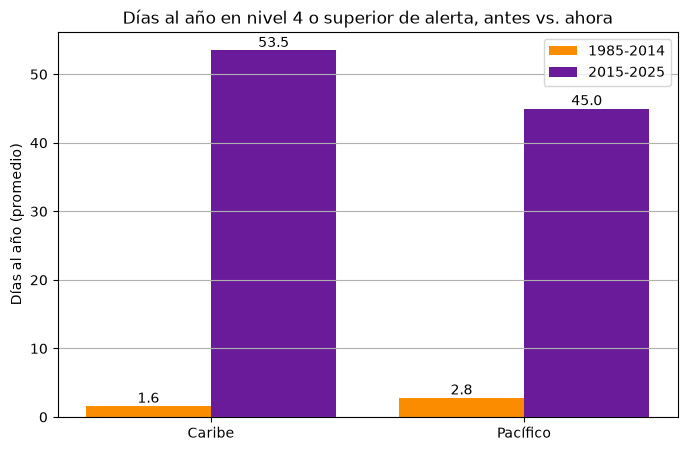

In [28]:
x = range(len(exposicion))
izq = [i - 0.2 for i in x]
der = [i + 0.2 for i in x]

fig, ax = plt.subplots(figsize=(8, 5))
antes = ax.bar(izq, exposicion["dias_n4_1985_2014"], width=0.4,
               label="1985-2014", color="#fb8c00")
ahora = ax.bar(der, exposicion["dias_n4_2015_2025"], width=0.4,
               label="2015-2025", color="#6a1b9a")

ax.bar_label(antes, fmt="%.1f")
ax.bar_label(ahora, fmt="%.1f")

ax.set_xticks(list(x), exposicion["costa"])
ax.set_title("Días al año en nivel 4 o superior de alerta, antes vs. ahora")
ax.set_ylabel("Días al año (promedio)")
ax.legend()
ax.grid(axis="y")
plt.show()

En ambas costas, los días al año con riesgo de mortalidad de corales pasaron de ser casi inexistentes
(menos de 3 días) a casi dos meses al año en la última década.

## 7. ¿Cómo va 2026? Observaciones extra:


In [29]:
corales["fecha"] = pd.to_datetime(corales["fecha"], utc=True)

ultimo = corales.sort_values("fecha", ascending=False).head(1)
ultimo[["fecha", "species", "costa", "institution_code", "basis_of_record"]]

,fecha,species,costa,institution_code,basis_of_record
117,2026-09-03 13:44:00+00:00,Diploria labyrinthiformis,Caribe,iNaturalist,HUMAN_OBSERVATION


In [30]:
corales_2026 = corales[corales["anio"] == 2026]

print("Registros de 2026:", len(corales_2026))
corales_2026[["fecha", "species", "costa", "zona", "institution_code"]].sort_values("fecha")

Registros de 2026: 165


,fecha,species,costa,zona,institution_code
148,2026-01-10 07:36:00+00:00,Colpophyllia natans,Caribe,sin dato,iNaturalist
157,2026-01-10 08:03:00+00:00,Diploria labyrinthiformis,Caribe,sin dato,iNaturalist
156,2026-01-10 08:11:00+00:00,Porites astreoides,Caribe,sin dato,iNaturalist
143,2026-01-10 08:14:00+00:00,Siderastrea siderea,Caribe,sin dato,iNaturalist
152,2026-01-10 13:49:00+00:00,Agaricia tenuifolia,Caribe,sin dato,iNaturalist
...,...,...,...,...,...
110,2026-07-22 14:36:00+00:00,Siderastrea siderea,Caribe,sin dato,iNaturalist
122,2026-07-23 17:09:00+00:00,Siderastrea siderea,Caribe,sin dato,iNaturalist
123,2026-07-24 07:40:45+00:00,Porites porites,Caribe,sin dato,iNaturalist
121,2026-07-24 08:22:10+00:00,Agaricia tenuifolia,Caribe,sin dato,iNaturalist


In [31]:
inat = corales[corales["institution_code"] == "iNaturalist"]
inat["anio"].value_counts().sort_index()

anio
2005.0      4
2007.0      7
2009.0      3
2010.0      9
2011.0      3
2012.0      6
2013.0      7
2014.0      2
2015.0      7
2016.0     25
2017.0     25
2018.0      9
2019.0     33
2020.0     21
2021.0      7
2022.0    104
2023.0     37
2024.0    202
2025.0    130
2026.0    165
Name: count, dtype: int64

In [32]:
datos_2026 = temperatura[temperatura["anio"] == 2026]

resumen_2026 = datos_2026.groupby("costa")["anomalia"].mean().round(2).reset_index()
resumen_2026 = resumen_2026.merge(
    semaforo[semaforo["anio"] == 2026][["costa", "dias_nivel_4", "alerta_max"]], on="costa"
)

print("Datos de temperatura hasta:", datos_2026["fecha"].max())
print("Observaciones de corales en iNaturalist en 2026:", len(corales_2026))
resumen_2026

Datos de temperatura hasta: 2026-11-05
Observaciones de corales en iNaturalist en 2026: 165


,costa,anomalia,dias_nivel_4,alerta_max
0,Caribe,1.06,28,5.0
1,Pacífico,1.41,149,6.0


Hasta la fecha de la última descarga, el Pacífico alcanzó en 2026 el nivel 6 (mortalidad severa) y acumula más días en nivel 4 o superior que el Caribe. Su anomalía promedio también es mayor. El año todavía no termina, así que estos valores pueden aumentar con la próxima descarga.

**Al momento de este análisis (datos hasta el 1 de noviembre de 2026):**
- **Pacífico:** la anomalía promedio es de +1.40 °C, más alta que la de cualquier año completo de la serie
(el máximo anterior fue +1.25 °C en 2023). Ya alcanzó el nivel 6 (mortalidad severa), el más alto
registrado en esa costa, y suma 145 días en nivel 4 o superior: más de tres veces el promedio anual
de 2015-2025 (45 días).
- **Caribe:** la anomalía promedio es de +1.06 °C, con 24 días en nivel 4 o superior.
- En iNaturalist se registraron 165 observaciones de corales en 2026.

Según NOAA (actualización del 8 de octubre de 2026), El Niño sigue fortaleciéndose, con un 83 % de probabilidad
de ser el más fuerte desde 1950 entre octubre y diciembre, y se espera que dure hasta inicios de 2027.
Este El Niño calienta sobre todo el Pacífico oriental, lo que explica por qué el Pacífico panameño va peor este año.
Como los meses que faltan coinciden con el pico de El Niño, es poco probable que la situación mejore antes de
terminar el año. Además, en los datos el Caribe suele tener su peor año justo después de un El Niño (como 2024),
por lo que 2027 podría ser también un año de alto riesgo para los corales del Caribe.

## 8. Conclusiones

Los datos muestran una vulnerabilidad clara en nuestros océanos. El calentamiento del mar en Panamá es evidente
y merece nuestra atención: la anomalía promedio pasó de 0.10 °C en los años 80 a 1.15 °C en los años 2020 en el
Caribe, y de 0.06 °C a 0.88 °C en el Pacífico. Desde 2002, ningún año ha estado por debajo de lo normal, y el
calentamiento avanza con o sin El Niño: cada evento llega a temperaturas más altas que el anterior, y hay años sin
El Niño, como 2020 en el Caribe, que llegó al nivel 5 de alerta. 

El estrés térmico ya no es una excepción. Desde 2023, ambas costas han alcanzado todos los años el nivel 4 de alerta o superior, y los días al año en esos niveles pasaron de menos de 3 a casi dos meses. En 2023, el Caribe llegó incluso al nivel 7 (mortalidad casi total), el máximo de la escala y el único caso en 42 años de datos.
Si bien un coral blanqueado puede recuperarse cuando la temperatura vuelve a la normalidad, el estrés prolongado
puede causar su muerte. Este riesgo no es exclusivo de una costa: en lo que va de 2026, el Pacífico ya alcanzó el nivel 6 (mortalidad severa) y suma 145 días en nivel 4 o superior, más de tres veces el promedio anual de 2015-2025 (45 días). Además, cada costa tiene corales únicos: las 49
especies registradas en el Caribe y las 18 del Pacífico no se comparten entre sí, por lo que lo que se pierde en una
costa no se recupera con la otra.

Lo positivo es que cada vez más personas, entre científicos y aficionados, están registrando corales: en iNaturalist,
2026 ya es el segundo año con más observaciones. Estas iniciativas podrían ampliarse, por ejemplo anotando la
profundidad, para medir el impacto del El Niño actual y del que venga después.

Aunque este estudio se enfoca en los corales, todo está conectado: los arrecifes son el hogar y la zona de crianza de
cientos de especies de peces, sostienen la pesca y el turismo de comunidades costeras, y protegen nuestras costas del
oleaje. Cuando los corales se debilitan, toda esa cadena se afecta. Por eso, como ciudadanos, debemos estar
atentos a cómo se toman las decisiones sobre la protección de nuestros océanos, como el proyecto de ley que se
discutió en 2026 sobre la protección de los arrecifes. Los datos abiertos nos permiten ver lo que está pasando;
lo que hagamos con esa información depende de todos.

### Limitaciones

- **Presencia, no abundancia:** los registros de GBIF indican que un coral fue visto en un lugar,
  no cuántos corales hay ni si están sanos.
- **Sesgo de muestreo:** el 95 % de los registros con año corresponde a 2002 (monitoreo de AGRRA en el Caribe),
  y no hay registros de corales **con profundidad anotada** durante los eventos de El Niño más fuertes  (2009-10, 2015-16, 2023-24).
  Por eso no se pudo comparar año por año.
- **Pocos datos del Pacífico:** el 61 % de sus registros no tiene profundidad y se excluyó;
  su diversidad podría estar subestimada.
- **NOAA estima el riesgo, no lo mide:** los niveles de alerta indican la probabilidad de blanqueamiento
  según la temperatura, no observaciones reales de corales blanqueados.
- **Las estaciones son áreas grandes:** cada costa se representa con 2 estaciones virtuales, que pueden
  no reflejar las condiciones exactas de cada arrecife.
- **2026 está incompleto:** se excluyó de los promedios anuales y por década.
- **Registros recientes sin profundidad:** las observaciones de iNaturalist (cientos al año desde 2022)
  no registran profundidad, por lo que no se incluyeron en el análisis.
- **Registros de museo dudosos:** algunos registros sin profundidad podrían ser corales profundos o datos antiguos
  difíciles de verificar.

## Fuentes
- Corales: GBIF, descarga 0041553-260928105237408.
- Temperatura: NOAA Coral Reef Watch, 5 km Regional Virtual Stations v3.1.
- Estado de El Niño: NOAA Climate Prediction Center, ENSO Diagnostic Discussion (8 de octubre de 2026).
- Arrecifes de Panamá y proyecto de ley: La Prensa, La Estrella de Panamá y Panamá América (2025-2026).

## 9. Guardar los datos para el dashboard

In [33]:
exposicion.to_csv("../datos/limpios/exposicion_por_costa.csv", index=False)
semaforo.to_csv("../datos/limpios/semaforo_por_anio.csv", index=False)
anual.to_csv("../datos/limpios/anomalia_por_anio.csv", index=False)
corales_costa.to_csv("../datos/limpios/corales_someros_por_costa.csv", index=False)

print("Archivos guardados para el dashboard")

Archivos guardados para el dashboard
